# ДЗ: пружинный маятник (редукция порядка и ДУ 2-го порядка)

В этом ДЗ две модели одной и той же механической системы: тележка на пружине без трения и с вязким трением. Обе описываются линейными ДУ **второго порядка**.

На семинаре мы изучали **понижение порядка** ДУ 2-го порядка. Общий метод решения линейных уравнений с постоянными коэффициентами (характеристическое уравнение) будет на следующем семинаре, поэтому здесь решать нужно **только** через `sympy.dsolve`, а графики строить **только** через `lambdify` и/или `matplotlib`.

Схема работы во всех подзадачах: `sp.Eq` → `sp.dsolve(..., ics=...)` → `sp.lambdify` → график. Скорость получайте как `sp.diff` от найденного решения.

## Задача 1. Тележка на пружине без трения

**Постановка.** Тележка массой $m$ стоит на горизонтальных рельсах и прикреплена пружиной жёсткости $k$ к неподвижной стене; другой конец тележки свободен. Трения нет. Тележку отводят от положения равновесия и отпускают (возможно, с начальной скоростью).

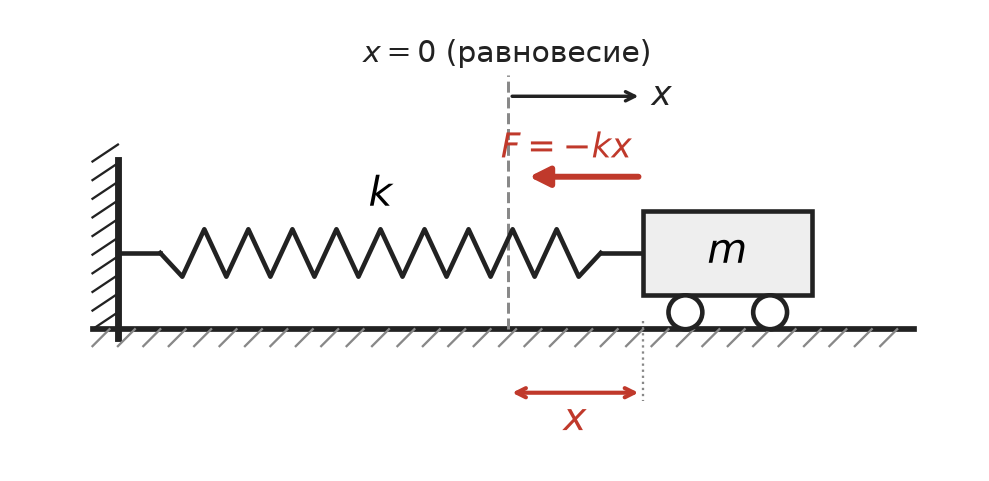

**Вывод ДУ (по шагам).**

1. *Координата.* Ось $x$ направим вдоль рельсов от стены. За начало отсчёта $x=0$ возьмём положение равновесия, то есть положение, в котором пружина имеет естественную длину (не растянута и не сжата). Тогда $x$ - это смещение тележки от равновесия, а удлинение пружины равно $x$: при $x>0$ пружина растянута, при $x<0$ сжата.
2. *Сила.* По закону Гука пружина действует на тележку силой, пропорциональной удлинению и направленной к положению равновесия:
$$F = -k\,x.$$
Знак «минус» означает, что сила всегда возвращает тележку назад. Вертикальные силы (тяжесть и реакция рельсов) друг друга уравновешивают и на движение вдоль рельсов не влияют.
3. *Второй закон Ньютона.* $m\,a = F$, где ускорение $a = x''$. Получаем
$$m\,x'' = -k\,x \quad\Longrightarrow\quad m\,x'' + k\,x = 0.$$
4. *Начальные условия.* В момент $t=0$ заданы положение и скорость:
$$x(0)=x_0,\qquad x'(0)=v(0)=v_0.$$

**Связь с семинаром (понижение порядка).** Время $t$ в уравнение явно не входит. Тогда можно взять $x$ за новую независимую переменную: $x' = p(x)$, и по правилу цепочки
$$x'' = \frac{dp}{dt} = \frac{dp}{dx}\cdot\frac{dx}{dt} = p\,\frac{dp}{dx}.$$
Уравнение превращается в уравнение 1-го порядка $m\,p\,\dfrac{dp}{dx} + k\,x = 0$, то есть $m\,p\,dp = -k\,x\,dx$. Интегрируя, получаем **интеграл энергии**
$$\frac{m\,p^2}{2} + \frac{k\,x^2}{2} = C = \frac{m\,v_0^2}{2} + \frac{k\,x_0^2}{2},$$
то есть сумма кинетической и потенциальной энергий сохраняется. Это уравнение связывает $v$ и $x$ и задаёт фазовую траекторию, но зависимость от времени $x(t)$ из него напрямую не получается.

**Параметры (одинаковы для всех подзадач):**

- масса $m = 1$ кг;
- начальное смещение $x_0 = 0{,}1$ м, начальная скорость $v_0 = 0$ м/с;
- жёсткости $k = 1,\ 4,\ 9,\ 16,\ 25$ Н/м;
- временной интервал для графиков: $t\in[0,\,10]$ с.

### Подзадачи

1. Решить ДУ $m x'' + k x = 0$ через `dsolve`: найти общее решение (с константами $C_1, C_2$) и частное решение с заданными н.у. Подставляйте числовые значения $m$ и $k$ до вызова `dsolve`.
2. Построить $x(t)$ для всех пяти значений $k$ на одном графике.
3. Построить скорость $v(t)=x'(t)$ для тех же $k$ на одном графике.
4. Построить фазовый портрет: $v$ как функция от $x$ для тех же $k$. Какая это кривая? Почему именно такая (вспомните интеграл энергии)?
5. **Вопрос.** Как период колебаний зависит от $k$? Оцените период по графику $x(t)$ и сравните с $T = 2\pi\sqrt{m/k}$. Зависит ли амплитуда колебаний от $k$ при данных начальных условиях?

## Задача 2. Тележка на пружине с вязким трением

**Постановка.** Та же тележка, но теперь на неё действует сила **вязкого трения** (сопротивления среды). Это трение, **пропорциональное скорости** и направленное против неё:
$$F_{тр} = -c\,v = -c\,x',\qquad c>0\ \text{(кг/с)}.$$
Это именно вязкое трение, а не сухое (кулоново): сухое трение имело бы постоянную величину и менялось бы только по знаку.

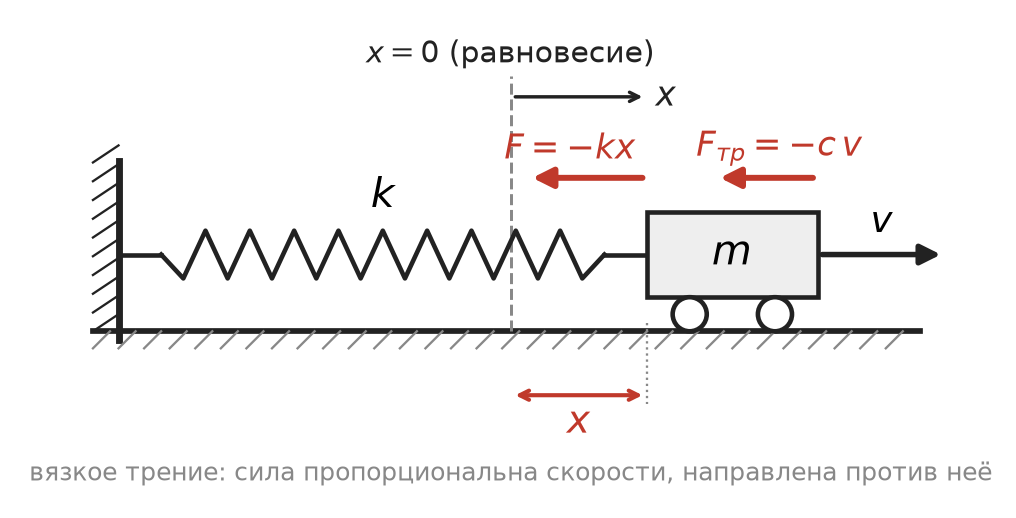

**Вывод ДУ.** Координата и сила упругости - как в задаче 1 ($x$ - смещение от положения равновесия, $F_{упр}=-kx$). Второй закон Ньютона для суммы сил:
$$m\,x'' = -k\,x - c\,x' \quad\Longrightarrow\quad m\,x'' + c\,x' + k\,x = 0,$$
с н.у. $x(0)=x_0$, $x'(0)=v_0$.

**О понижении порядка.** Время снова явно не входит, и подстановка $x'=p(x)$, $x''=p\,p'$ даёт $m\,p\,\dfrac{dp}{dx} + c\,p + k\,x = 0$. Но теперь это нелинейное уравнение 1-го порядка, и оно даёт лишь фазовую траекторию $p(x)$, а не $x(t)$. Полный метод решения (характеристическое уравнение) будет на следующем семинаре; пока решаем через SymPy.

**Параметры:**

- $m = 1$ кг, $x_0 = 0{,}1$ м, $v_0 = 0$ м/с (как в задаче 1);
- семейство по $k$ (при фиксированном $c = 1$ кг/с): $k = 1,\ 4,\ 9,\ 16,\ 25$ Н/м;
- семейство по $c$ (при фиксированном $k = 4$ Н/м): $c = 0{,}5,\ 1,\ 2,\ 4,\ 8$ кг/с;
- временной интервал: $t\in[0,\,10]$ с.

Значения $c$ выбраны специально, чтобы охватить три режима при $k=4$: слабое затухание $c<2\sqrt{km}$, ровно критическое $c=2\sqrt{km}$ и сильное $c>2\sqrt{km}$.

> **Подсказка.** Если решать `dsolve` с символьными $c$, $k$, $m$, формула содержит $\sqrt{c^2-4km}$ и «ломается» при $c = c_{кр}$ (деление на ноль, а при $c<c_{кр}$ - комплексный корень). Поэтому **подставляйте числа до вызова `dsolve`**: для каждого набора параметров решайте своё уравнение.

### Подзадачи

1. Решить ДУ $m x'' + c x' + k x = 0$ через `dsolve` (общее решение и частное с н.у.) для конкретных чисел, например $k=4$, $c=1$.
2. Построить $x(t)$: (а) при $c=1$ для пяти значений $k$; (б) при $k=4$ для пяти значений $c$. Два отдельных графика.
3. Построить $v(t)$ для тех же двух семейств (ещё два графика).
4. Построить фазовый портрет $v(x)$ для семейства по $c$ (при $k=4$). Чем отличаются кривые при слабом и сильном затухании (спираль или нет)?
5. **Вопрос о критическом затухании.** При каком $c$ тележка перестаёт совершать колебания, то есть больше не проходит через положение равновесия? Получите условие $c_{кр}=2\sqrt{km}$ из графиков и решений. Что происходит при $c<c_{кр}$, $c=c_{кр}$, $c>c_{кр}$? В каком режиме тележка быстрее всего возвращается к равновесию?